In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, auc, classification_report

# Загрузка
df = pd.read_csv('processed_spotify_data.csv')

# Создаем бинарную цель (Популярный / Непопулярный)
median_pop = df['popularity'].median()
df['is_popular'] = (df['popularity'] >= median_pop).astype(int)

# Убираем утечку данных
cols_to_drop = ['popularity', 'is_popular', 'popularity_category_Low', 
                'popularity_category_Medium', 'popularity_category_Very High',
                'stream_count', 'log_stream_count']
X = df.drop(columns=cols_to_drop)
y = df['is_popular']

# Разделение
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Данные готовы. Обучающая: {X_train.shape[0]}, Тестовая: {X_test.shape[0]}")


Данные готовы. Обучающая: 40000, Тестовая: 10000


In [8]:
from sklearn.ensemble import RandomForestClassifier

print("--- Задание 2: Случайный лес (Random Forest) ---")

# Увеличиваем количество деревьев и глубину, 
# а также уменьшаем min_samples_leaf, чтобы дать модели больше свободы
rf_model = RandomForestClassifier(
    n_estimators=200, 
    max_depth=20,          # Позволяем деревьям быть глубже
    min_samples_leaf=2,    # Разрешаем листьям быть маленькими
    oob_score=True, 
    random_state=42, 
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print(f"OOB Accuracy (Точность): {rf_model.oob_score_:.4f}")
print(f"OOB Error (Ошибка): {1 - rf_model.oob_score_:.4f}")

y_proba_rf = rf_model.predict_proba(X_test)[:, 1]

--- Задание 2: Случайный лес (Random Forest) ---
OOB Accuracy (Точность): 0.5696
OOB Error (Ошибка): 0.4304


In [9]:
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier

print("--- Задание 3: AdaBoost и Градиентный бустинг ---")

# 1. Модель AdaBoost
ada_model = AdaBoostClassifier(n_estimators=100, random_state=42)
ada_model.fit(X_train, y_train)
y_proba_ada = ada_model.predict_proba(X_test)[:, 1]
print("Модель AdaBoost обучена.")

# 2. Модель Градиентного бустинга
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)
y_proba_gb = gb_model.predict_proba(X_test)[:, 1]
print("Модель Gradient Boosting обучена.")


--- Задание 3: AdaBoost и Градиентный бустинг ---
Модель AdaBoost обучена.
Модель Gradient Boosting обучена.


--- Задание 4: Оценка и ROC-кривые ---


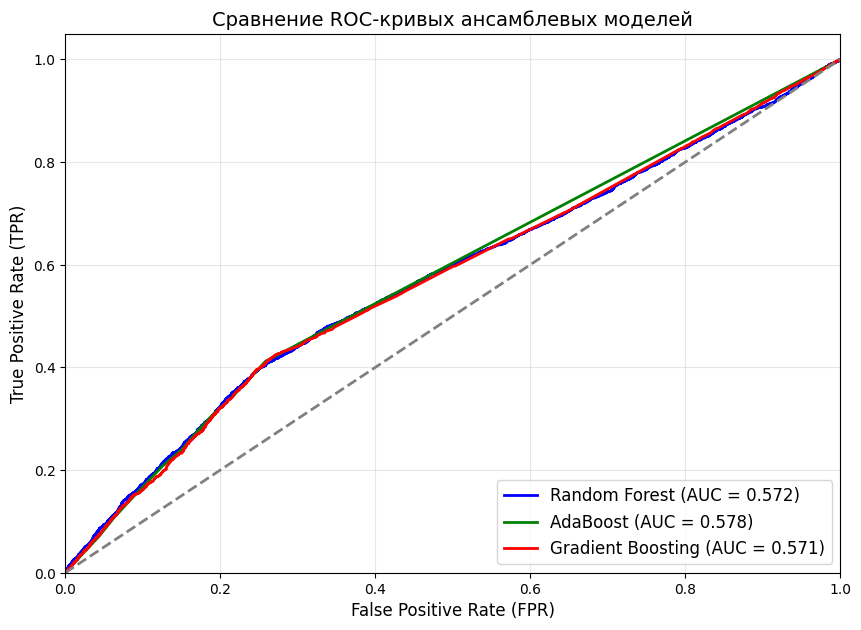


Classification Report (Gradient Boosting):
              precision    recall  f1-score   support

           0       0.55      0.74      0.63      4909
           1       0.62      0.41      0.50      5091

    accuracy                           0.57     10000
   macro avg       0.58      0.58      0.56     10000
weighted avg       0.59      0.57      0.56     10000



In [10]:
print("--- Задание 4: Оценка и ROC-кривые ---")

# Считаем ROC-кривые для всех трех моделей
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)
auc_rf = auc(fpr_rf, tpr_rf)

fpr_ada, tpr_ada, _ = roc_curve(y_test, y_proba_ada)
auc_ada = auc(fpr_ada, tpr_ada)

fpr_gb, tpr_gb, _ = roc_curve(y_test, y_proba_gb)
auc_gb = auc(fpr_gb, tpr_gb)

# Строим общий график
plt.figure(figsize=(10, 7))

plt.plot(fpr_rf, tpr_rf, color='blue', lw=2, label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot(fpr_ada, tpr_ada, color='green', lw=2, label=f'AdaBoost (AUC = {auc_ada:.3f})')
plt.plot(fpr_gb, tpr_gb, color='red', lw=2, label=f'Gradient Boosting (AUC = {auc_gb:.3f})')

# Линия случайного угадывания
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Сравнение ROC-кривых ансамблевых моделей', fontsize=14)
plt.legend(loc="lower right", fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()

# Вывод текстового отчета по лучшей модели (Gradient Boosting)
print("\nClassification Report (Gradient Boosting):")
print(classification_report(y_test, gb_model.predict(X_test)))